# 05 — Topologischer Struktur-Break-Detektor

**Zweck:** Herleitung + systematische Analyse des Verfahrens aus `docs/project/woo_2026a_additional-information.pdf` (Abschnitt 2, "Second phase: out-of-sample backtest & structural integrity monitoring"). Die eigentliche Engine-Integration (`TopologicalBreakRule` in `src/backtest/exit_rules.py`, `Position.entry_death`, `BasketParams.topo_break_*`) ist inzwischen umgesetzt -- dieses Notebook bleibt die Herleitung/Doku dafür und liefert zusätzlich die Kennzahlen (Zensierungsrate, Auslöse-Häufigkeit), auf die der Code-Kommentar in `exit_rules.TopologicalBreakRule` verweist.

**Kernidee des PDFs:** beim Entry einer Position wird der `death`-Wert (ε*) der gehandelten Clique aus der TDA-Discovery gespeichert (seit dieser Analyse auch in `data/processed/cliques/*.parquet` gecacht, Spalte `death`). Statt bei jedem folgenden Zeitschritt die volle Vietoris-Rips-Filtration über das gesamte Asset-Universum neu zu berechnen, wird NUR für die Assets der offenen Clique eine Single-Linkage-Hierarchie (`scipy.cluster.hierarchy.linkage(method="single")`) auf der aktuellen Korrelationsdistanzmatrix gebaut und bei `τ = ε* - δ` geschnitten (`scipy.cluster.hierarchy.fcluster`). Bleiben alle Assets in einem Cluster, ist die Struktur intakt; zerfällt die Clique, ist das der Struktur-Break -- ein deutlich günstigerer Ersatz für eine volle Neu-Discovery bei jedem Zeitschritt.

Dieses Notebook:
1. lädt eine echte, bereits discoverte Clique aus dem Cache (`04_clique_cache.ipynb`) als konkretes Beispiel,
2. baut das Dendrogramm-Beispiel aus dem PDF mit echten Daten nach,
3. misst die Zensierungsrate (`death == epsilon_cap`) über den KOMPLETTEN Cache (alle Baskets x alle 6 Varianten -- jetzt möglich, da `death` gecacht ist, keine Neuberechnung nötig),
4. simuliert die rollierende Integritätsprüfung nach dem (fiktiven) Entry-Zeitpunkt, systematisch über mehrere Beispiel-Cliquen pro Basket,
5. vergleicht, wann dieser Struktur-Break im Vergleich zum simplen Mitgliedschaftswechsel (`exit_on_clique_break`) ausgelöst hätte,
6. testet die Sensitivität von `δ` (delta) und der Rolling-Window-Länge.


In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("../..").resolve()))

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform

from src.config import (
    ASSET_DAILY_PATH,
    ASSET_ID_COL,
    ASSETS_PATH,
    CLOSE_COL,
    DATE_COL,
    MARKET_SYMBOL_COL,
    OHLCV_DIR,
    PROCESSED_DIR,
    TIMESTAMP_COL,
    VOLUME_COL,
)
from src.clustering.helpers import HelperFunctions, STABLECOIN_SYMBOLS

helper = HelperFunctions()

print("Imports OK")


Imports OK


# 2. Daten laden

In [2]:
# --- Daten laden & vorverarbeiten (identisch zu 02_pointclouds.ipynb / 04_clique_cache.ipynb) ---
assets_df = pd.read_parquet(ASSETS_PATH)[["asset_id", "symbol"]].drop_duplicates()
id_to_symbol = dict(zip(assets_df["asset_id"], assets_df["symbol"]))
sym_to_id = dict(zip(assets_df["symbol"], assets_df["asset_id"]))

excluded_ids_stablecoins: set[int] = set(
    assets_df.loc[assets_df["symbol"].isin(STABLECOIN_SYMBOLS), "asset_id"].tolist()
)

ohlcv_files = sorted(OHLCV_DIR.glob("*.parquet"))
raw = pd.concat([pd.read_parquet(f) for f in ohlcv_files], ignore_index=True)
raw["base_symbol"] = raw[MARKET_SYMBOL_COL].str.replace("USDT$", "", regex=True)
raw = raw.merge(assets_df.rename(columns={"symbol": "base_symbol"}), on="base_symbol", how="left")
raw = raw.dropna(subset=["asset_id"])
raw["asset_id"] = raw["asset_id"].astype(int)
raw[TIMESTAMP_COL] = pd.to_datetime(raw[TIMESTAMP_COL], utc=True)
raw[DATE_COL] = raw[TIMESTAMP_COL].dt.normalize()
ohlcv_df = raw[[TIMESTAMP_COL, DATE_COL, ASSET_ID_COL, CLOSE_COL]].copy()

data_min = ohlcv_df[DATE_COL].min()
data_max = ohlcv_df[DATE_COL].max()

universe_df = pd.read_parquet(ASSET_DAILY_PATH)
universe_df[DATE_COL] = pd.to_datetime(universe_df[DATE_COL], utc=True)
all_asset_ids_local = set(universe_df[ASSET_ID_COL].unique())

print(f"Zeitraum: {data_min.date()} → {data_max.date()}")


Zeitraum: 2024-07-23 → 2026-07-22


# 3. Eine echte Clique als Beispiel laden

Nutzt einen der sechs Caches aus `04_clique_cache.ipynb`. Für die Monitoring-Simulation unten braucht die gewählte Clique genug Folgedaten NACH ihrem Discovery-Zeitpunkt -- deshalb wird bewusst ein Zeitpunkt in der ersten Hälfte des verfügbaren Zeitraums gewählt, nicht der neueste Eintrag.

In [3]:
EXAMPLE_VARIANT = "raw_24h"
EXAMPLE_BASKET = "Basket 4"

cliques_df = pd.read_parquet(PROCESSED_DIR / "cliques" / f"cliques_{EXAMPLE_VARIANT}.parquet")
cliques_df["discovery_date"] = pd.to_datetime(cliques_df["discovery_date"], utc=True)
basket_cliques = cliques_df.loc[cliques_df["basket"] == EXAMPLE_BASKET].sort_values("discovery_date").reset_index(drop=True)

# Beispiel-Zeile: min. 5 Assets, aus der ersten Hälfte des Zeitraums (genug
# "Zukunft" für die Monitoring-Simulation unten), UND nahe dem MEDIAN der
# Persistenz-Verteilung -- eine sehr hohe Persistenz deutet meist auf einen
# Basket-Tag mit genau so vielen Assets wie die Clique selbst hin (die Clique
# IST dann die Baum-Wurzel, deren "death" per Definition bei epsilon_cap
# zensiert ist -- kein informatives Beispiel für die Bruch-Dynamik unten).
candidate_rows = basket_cliques.iloc[: len(basket_cliques) // 2]
candidate_rows = candidate_rows.loc[candidate_rows["size"] >= 5].sort_values("persistence").reset_index(drop=True)
example_row = candidate_rows.iloc[len(candidate_rows) // 2]

EXAMPLE_DISCOVERY_TS = pd.Timestamp(example_row["discovery_date"])
EXAMPLE_LOOKBACK_DAYS = int(example_row["lookback_days"])
CACHED_PERSISTENCE = float(example_row["persistence"])  # death - birth, siehe Abschnitt 4 fuer die Einordnung
CACHED_DEATH = float(example_row["death"])  # = epsilon*, jetzt direkt gecacht (siehe 04_clique_cache.ipynb)
CACHED_ASSET_IDS = sorted(int(a) for a in example_row["asset_ids"])
EXAMPLE_EPSILON_CAP = 1.0 if EXAMPLE_VARIANT.startswith("raw") else 1.3

print(f"Beispiel-Clique ({EXAMPLE_VARIANT}, {EXAMPLE_BASKET}):")
print(f"  Discovery:            {EXAMPLE_DISCOVERY_TS}")
print(f"  Assets (aus Cache):   {[id_to_symbol[a] for a in CACHED_ASSET_IDS]}")
print(f"  Lookback:             {EXAMPLE_LOOKBACK_DAYS} Tage")
print(f"  Persistence (Cache):  {CACHED_PERSISTENCE:.4f}  (= death - birth)")
print(f"  Death (Cache, =eps*): {CACHED_DEATH:.4f}  (zensiert={'ja' if abs(CACHED_DEATH - EXAMPLE_EPSILON_CAP) < 1e-9 else 'nein'})")


Beispiel-Clique (raw_24h, Basket 4):
  Discovery:            2025-06-21 00:00:00+00:00
  Assets (aus Cache):   ['ALGO', 'ATOM', 'ICP', 'POL', 'RENDER']
  Lookback:             5 Tage
  Persistence (Cache):  0.3412  (= death - birth)
  Death (Cache, =eps*): 1.0000  (zensiert=ja)


# 4. Nachbau PDF-Beispiel: Dendrogramm bei Discovery

Wie im PDF (Seite 4-5, "Visual Example: 5-Asset Clique Dendrogram"): Single-Linkage-Dendrogramm über ALLE Basket-Assets zum Discovery-Zeitpunkt (nicht nur die Clique-Mitglieder) -- so wird sichtbar, dass der horizontale Schnitt bei `ε* = death` genau die discoverte Clique isoliert, während andere Basket-Assets (falls vorhanden) erst bei höherer Distanz dazustossen.

**Wichtiger Befund beim Nachbau:** `CliqueSnapshot.persistence` (= das, was im Cache steht) ist **nicht** dasselbe wie `ε*` im Sinne des PDFs! Der Docstring von `CliqueSnapshot.persistence` behauptet "H0: birth immer 0", das stimmt aber nur für ein einzelnes, nie verschmolzenes Asset (einen Blatt-Knoten). `HelperFunctions.get_persistent_clusters` verlangt `min_cluster_size=2` -- der Gewinner-Knoten ist deshalb IMMER ein interner Merge-Knoten, dessen `birth` die Höhe ist, bei der genau diese Asset-Gruppe zuerst entstand (nicht 0). `persistence = death - birth` ist deshalb systematisch KLEINER als `death` (ausser birth=0 zufällig). Für den Struktur-Break-Detektor (τ = ε* - δ) muss aber `death` verwendet werden, nicht `persistence` -- ein Schnitt bei `persistence - δ` würde deutlich zu früh (zu flach) schneiden und ständig fälschlich "fragmentiert" melden. Dieses Notebook rechnet deshalb `death` unten direkt neu aus (`get_persistent_clusters` liefert `birth`/`death`/`persistence` einzeln), statt sich auf den gecachten `persistence`-Wert zu verlassen -- der Cache müsste um ein `death`-Feld erweitert werden, bevor `TopologicalBreakRule` das produktiv nutzen kann (siehe Fazit, Abschnitt 7).

Rekonstruierte Clique: ['ALGO', 'ATOM', 'ICP', 'POL', 'RENDER']
  stimmt mit Cache ueberein: True
  birth=0.6588  death (=epsilon*)=1.0000  persistence(death-birth)=0.3412
  gecachte persistence war 0.3412 -- stimmt ueberein mit death-birth oben
  gecachtes death war 1.0000 -- stimmt ueberein mit neu berechnetem death


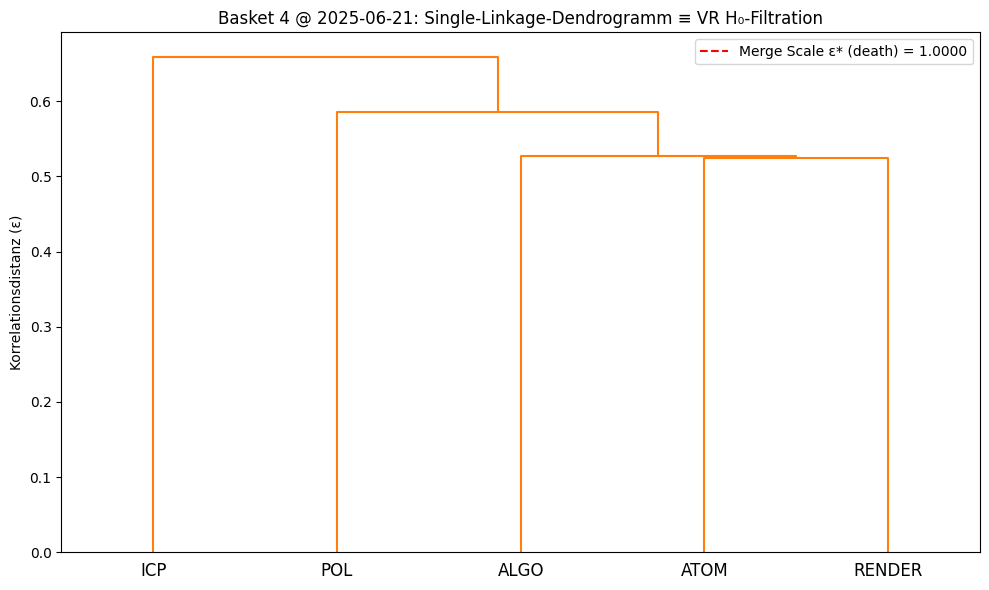


Cluster beim Schnitt knapp unter epsilon* (=death):
  ['ALGO', 'ATOM', 'ICP', 'POL', 'RENDER'] <- Clique


In [4]:
# Basket-Zugehörigkeit am Discovery-Tag (Tageszugehörigkeit, wie überall sonst im Projekt).
POINTCLOUD_BASKET_UPPER_BOUNDS = [100_000_000, 250_000_000, 1_000_000_000]
POINTCLOUD_LOOKBACK_DAYS = 7
rolling_volume_df = helper.compute_rolling_volume_table(
    universe_df, id_column=ASSET_ID_COL, date_column=DATE_COL,
    volume_column=VOLUME_COL, lookback_days=POINTCLOUD_LOOKBACK_DAYS,
)
basket_df_at_discovery = helper.build_volume_baskets(
    rolling_volume_df, EXAMPLE_DISCOVERY_TS.normalize(), id_column=ASSET_ID_COL, date_column=DATE_COL,
    basket_upper_bounds=POINTCLOUD_BASKET_UPPER_BOUNDS,
)
basket_asset_ids_at_discovery = sorted(
    basket_df_at_discovery.loc[basket_df_at_discovery["basket"] == EXAMPLE_BASKET, ASSET_ID_COL]
)
basket_exclude_ids = excluded_ids_stablecoins | (all_asset_ids_local - set(basket_asset_ids_at_discovery))

res_discovery = helper.build_point_cloud(
    ohlcv_df=ohlcv_df, universe_df=universe_df, end_date=EXAMPLE_DISCOVERY_TS,
    window_size_days=EXAMPLE_LOOKBACK_DAYS, exclude_asset_ids=basket_exclude_ids,
)
dist_discovery = helper.correlation_distance(pd.DataFrame(res_discovery["point_cloud"]))
labels_discovery = [id_to_symbol[a] for a in res_discovery["asset_ids"]]

# get_persistent_clusters mit persistence_threshold=0.0 -- findet denselben
# Gewinner-Knoten wie die echte (kalibrierte) Discovery (der Threshold ist nur
# eine Mindestschwelle, veraendert das Argmax nicht), liefert zusaetzlich aber
# birth/death einzeln statt nur die gecachte persistence-Differenz.
clusters_discovery, Z_discovery = helper.get_persistent_clusters(
    dist_discovery, res_discovery["asset_ids"], persistence_threshold=0.0, epsilon_cap=1.0,
)
cluster_discovery = clusters_discovery[0]
EXAMPLE_ASSET_IDS = sorted(cluster_discovery["asset_ids"])
EXAMPLE_SYMBOLS = [id_to_symbol[a] for a in EXAMPLE_ASSET_IDS]
EPSILON_BIRTH = cluster_discovery["birth"]
EPSILON_STAR = cluster_discovery["death"]  # das eigentliche PDF-epsilon*, NICHT cluster_discovery["persistence"]

print(f"Rekonstruierte Clique: {EXAMPLE_SYMBOLS}")
print(f"  stimmt mit Cache ueberein: {EXAMPLE_ASSET_IDS == CACHED_ASSET_IDS}")
print(f"  birth={EPSILON_BIRTH:.4f}  death (=epsilon*)={EPSILON_STAR:.4f}  persistence(death-birth)={cluster_discovery['persistence']:.4f}")
print(f"  gecachte persistence war {CACHED_PERSISTENCE:.4f} -- {'stimmt ueberein' if abs(cluster_discovery['persistence'] - CACHED_PERSISTENCE) < 1e-6 else 'WEICHT AB'} mit death-birth oben")
print(f"  gecachtes death war {CACHED_DEATH:.4f} -- {'stimmt ueberein' if abs(cluster_discovery['death'] - CACHED_DEATH) < 1e-6 else 'WEICHT AB'} mit neu berechnetem death")

fig, ax = plt.subplots(figsize=(10, 6))
dendrogram(Z_discovery, labels=labels_discovery, color_threshold=EPSILON_STAR, above_threshold_color="grey", ax=ax)
ax.axhline(y=EPSILON_STAR, color="r", linestyle="--", label=f"Merge Scale ε* (death) = {EPSILON_STAR:.4f}")
ax.set_ylabel("Korrelationsdistanz (ε)")
ax.set_title(f"{EXAMPLE_BASKET} @ {EXAMPLE_DISCOVERY_TS.date()}: Single-Linkage-Dendrogramm ≡ VR H₀-Filtration")
ax.legend()
plt.tight_layout()
plt.show()

# Sanity-Check: Schnitt bei epsilon*-tiny sollte jetzt (mit dem korrekten
# death-Wert statt der gecachten persistence) genau die Clique isolieren.
cut_labels = fcluster(Z_discovery, t=EPSILON_STAR - 1e-9, criterion="distance")
cut_groups: dict[int, list[str]] = {}
for lab, sym in zip(cut_labels, labels_discovery):
    cut_groups.setdefault(lab, []).append(sym)
print("\nCluster beim Schnitt knapp unter epsilon* (=death):")
for lab, syms in cut_groups.items():
    marker = " <- Clique" if set(syms) == set(EXAMPLE_SYMBOLS) else ""
    print(f"  {syms}{marker}")


**Wie häufig ist `death` zensiert (== `epsilon_cap`)?** Jetzt, wo `death` gecacht ist (`04_clique_cache.ipynb`, Spalte `death`), lässt sich das exakt über den KOMPLETTEN Cache auswerten -- alle Baskets x alle 6 Varianten (roh/residualisiert x 6h/12h/24h) -- statt wie zuvor an einer kleinen, teuer neu berechneten Stichprobe zu schätzen.

In [5]:
CENSOR_EPS = 1e-9
_epsilon_cap_by_kind = {"raw": 1.0, "residual": 1.3}

censor_rows = []
for kind, epsilon_cap_kind in _epsilon_cap_by_kind.items():
    for h in [6, 12, 24]:
        variant = f"{kind}_{h}h"
        df = pd.read_parquet(PROCESSED_DIR / "cliques" / f"cliques_{variant}.parquet")
        for label in sorted(df["basket"].unique()):
            sub = df.loc[df["basket"] == label]
            censor_rows.append({
                "variant": variant,
                "basket": label,
                "n": len(sub),
                "pct_censored": float((sub["death"] >= epsilon_cap_kind - CENSOR_EPS).mean()),
                "median_death": float(sub["death"].median()),
                "epsilon_cap": epsilon_cap_kind,
            })

censor_df = pd.DataFrame(censor_rows)
pivot_pct = censor_df.pivot(index="basket", columns="variant", values="pct_censored")
pivot_pct = pivot_pct[[f"{k}_{h}h" for k in ["raw", "residual"] for h in [6, 12, 24]]]

print("Anteil zensierter death-Werte (== epsilon_cap), pro Basket x Variante:")
print((pivot_pct * 100).round(1).to_string())
print()
print(f"Gesamt (alle Baskets/Varianten gepoolt): {100 * censor_df['pct_censored'].mul(censor_df['n']).sum() / censor_df['n'].sum():.1f}% zensiert, ueber {censor_df['n'].sum()} Cliquen.")


Anteil zensierter death-Werte (== epsilon_cap), pro Basket x Variante:
variant   raw_6h  raw_12h  raw_24h  residual_6h  residual_12h  residual_24h
basket                                                                     
Basket 1    80.7     80.7     80.4         52.6          52.7          52.7
Basket 2    38.7     38.5     38.2         33.9          34.1          33.7
Basket 3    62.3     62.7     62.7         71.8          72.1          73.2
Basket 4    79.8     79.7     80.9         69.7          70.0          69.6

Gesamt (alle Baskets/Varianten gepoolt): 58.6% zensiert, ueber 20817 Cliquen.


# 5. Monitoring-Nachbau: rollierende Struktur-Integritätsprüfung nach Entry

Ab `EXAMPLE_DISCOVERY_TS` (Stand-in für einen Entry-Zeitpunkt) wird stündlich geprüft, ob die Clique bei `τ = ε* - δ` noch als EIN Cluster zusammenhängt. Nur die Assets der Clique selbst werden dafür verwendet (`exclude_asset_ids` = alles andere) -- kein Basket-weiter Re-Discovery-Schritt, exakt das im PDF beschriebene Effizienz-Argument.

Zum Vergleich: der nächste Zeitpunkt, an dem sich die discoverte Mitgliedschaft dieses Baskets tatsächlich ändert (das bereits in der Engine existierende `exit_on_clique_break`, reiner Mengenvergleich der Asset-IDs) -- zeigt, ob der topologische Break früher/später/gleichzeitig ausgelöst hätte.

In [6]:
DELTA = 0.001  # wie im PDF-Beispiel
MONITOR_WINDOW_DAYS = EXAMPLE_LOOKBACK_DAYS  # rollierendes Fenster fuer die Live-Distanzmatrix
MONITOR_STEP_HOURS = 1
MONITOR_HORIZON_DAYS = 30

tau = EPSILON_STAR - DELTA
monitor_exclude_ids = excluded_ids_stablecoins | (all_asset_ids_local - set(EXAMPLE_ASSET_IDS))
monitor_end = min(EXAMPLE_DISCOVERY_TS + pd.Timedelta(days=MONITOR_HORIZON_DAYS), data_max)
monitor_dates = pd.date_range(EXAMPLE_DISCOVERY_TS, monitor_end, freq=f"{MONITOR_STEP_HOURS}h", tz="UTC")

t0 = time.time()
monitor_records = []  # (timestamp, fragmented, n_clusters)
Z_by_step: dict[pd.Timestamp, np.ndarray] = {}  # fuer die Sensitivitaetsanalyse unten wiederverwendet
for t in monitor_dates:
    res = helper.build_point_cloud(
        ohlcv_df=ohlcv_df, universe_df=universe_df, end_date=t,
        window_size_days=MONITOR_WINDOW_DAYS, exclude_asset_ids=monitor_exclude_ids,
    )
    if res is None or res["n_dimensions"] < len(EXAMPLE_ASSET_IDS):
        continue  # z.B. Datenlücke -- Assets nicht mehr vollständig verfügbar
    dist_t = helper.correlation_distance(pd.DataFrame(res["point_cloud"]))
    Z_t = linkage(squareform(dist_t, checks=False), method="single")
    Z_by_step[t] = Z_t
    labels_t = fcluster(Z_t, t=tau, criterion="distance")
    fragmented = len(set(labels_t)) > 1
    monitor_records.append((t, fragmented, len(set(labels_t))))

runtime_s = time.time() - t0
monitor_df = pd.DataFrame(monitor_records, columns=["timestamp", "fragmented", "n_clusters"])
print(f"{len(monitor_df)} Zeitschritte geprüft in {runtime_s:.1f}s ({MONITOR_STEP_HOURS}h-Schritte über {MONITOR_HORIZON_DAYS} Tage)")

first_topo_break = monitor_df.loc[monitor_df["fragmented"], "timestamp"].min()
if pd.isna(first_topo_break):
    print(f"Kein topologischer Struktur-Break innerhalb von {MONITOR_HORIZON_DAYS} Tagen (delta={DELTA}).")
else:
    hours_to_break = (first_topo_break - EXAMPLE_DISCOVERY_TS).total_seconds() / 3600
    print(f"Erster topologischer Struktur-Break: {first_topo_break} ({hours_to_break:.1f}h nach Discovery)")

# --- Vergleich: naechster reiner Mitgliedschaftswechsel (exit_on_clique_break) ---
later_rows = basket_cliques.loc[basket_cliques["discovery_date"] > EXAMPLE_DISCOVERY_TS]
example_key = frozenset(EXAMPLE_ASSET_IDS)
membership_break_row = later_rows.loc[
    later_rows["asset_ids"].apply(lambda ids: frozenset(int(a) for a in ids) != example_key)
].head(1)
if membership_break_row.empty:
    print("Kein Mitgliedschaftswechsel im restlichen Cache-Zeitraum gefunden.")
else:
    membership_break_ts = pd.Timestamp(membership_break_row.iloc[0]["discovery_date"])
    hours_to_membership_break = (membership_break_ts - EXAMPLE_DISCOVERY_TS).total_seconds() / 3600
    print(f"Naechster Mitgliedschaftswechsel (clique_break): {membership_break_ts} ({hours_to_membership_break:.1f}h nach Discovery)")


457 Zeitschritte geprüft in 18.8s (1h-Schritte über 30 Tage)
Kein topologischer Struktur-Break innerhalb von 30 Tagen (delta=0.001).
Naechster Mitgliedschaftswechsel (clique_break): 2025-06-22 00:00:00+00:00 (24.0h nach Discovery)


## Systematische Trigger-Häufigkeit über mehrere Beispiele pro Basket

Statt nur der einen Beispiel-Clique oben: pro Basket mehrere (gleichmässig über die Persistenz-Verteilung verteilte) Discovery-Zeitpunkte aus der ersten Hälfte des Zeitraums ziehen, jeweils bis zu 30 Tage rollierend prüfen (δ=0.001, Fenster = Lookback der jeweiligen Clique, gröberer Zeitschritt als oben um die Laufzeit im Rahmen zu halten), und aggregieren: Anteil, der überhaupt auslöst, Median-Zeit-bis-Break, im Vergleich zum reinen Mitgliedschaftswechsel (`clique_break`). `death` kommt jetzt direkt aus dem Cache -- keine Neuberechnung der Discovery selbst nötig, nur die rollierende Monitoring-Simulation danach.

In [7]:
basket_labels = sorted(cliques_df["basket"].unique())
N_EXAMPLES_PER_BASKET = 5
MONITOR_HORIZON_DAYS_MULTI = 30
DELTA_MULTI = 0.001
MONITOR_STEP_HOURS_MULTI = 2  # groeber als Abschnitt 5, um die Laufzeit im Rahmen zu halten


def _pick_example_rows(label, n):
    basket_rows = cliques_df.loc[cliques_df["basket"] == label].sort_values("discovery_date").reset_index(drop=True)
    candidates = basket_rows.iloc[: len(basket_rows) // 2]
    candidates = candidates.loc[candidates["size"] >= 3].sort_values("persistence").reset_index(drop=True)
    if len(candidates) == 0:
        return candidates
    idx = np.linspace(0, len(candidates) - 1, num=min(n, len(candidates)), dtype=int)
    return candidates.iloc[idx]


multi_records = []
t0_multi = time.time()
for label in basket_labels:
    for _, row in _pick_example_rows(label, N_EXAMPLES_PER_BASKET).iterrows():
        asset_ids = sorted(int(a) for a in row["asset_ids"])
        discovery_ts = pd.Timestamp(row["discovery_date"])
        death_val = float(row["death"])
        lb = int(row["lookback_days"])
        exclude_ids = excluded_ids_stablecoins | (all_asset_ids_local - set(asset_ids))
        tau_m = death_val - DELTA_MULTI

        monitor_end = min(discovery_ts + pd.Timedelta(days=MONITOR_HORIZON_DAYS_MULTI), data_max)
        monitor_dates_m = pd.date_range(discovery_ts, monitor_end, freq=f"{MONITOR_STEP_HOURS_MULTI}h", tz="UTC")

        first_break = None
        for t in monitor_dates_m:
            res_m = helper.build_point_cloud(
                ohlcv_df=ohlcv_df, universe_df=universe_df, end_date=t,
                window_size_days=lb, exclude_asset_ids=exclude_ids,
            )
            if res_m is None or res_m["n_dimensions"] < len(asset_ids):
                continue
            dist_m = helper.correlation_distance(pd.DataFrame(res_m["point_cloud"]))
            z_m = linkage(squareform(dist_m, checks=False), method="single")
            labels_m = fcluster(z_m, t=tau_m, criterion="distance")
            if len(set(labels_m)) > 1:
                first_break = t
                break

        basket_rows_all = cliques_df.loc[cliques_df["basket"] == label].sort_values("discovery_date")
        later = basket_rows_all.loc[basket_rows_all["discovery_date"] > discovery_ts]
        key = frozenset(asset_ids)
        membership_break = later.loc[later["asset_ids"].apply(lambda ids: frozenset(int(a) for a in ids) != key)].head(1)
        membership_break_ts = pd.Timestamp(membership_break.iloc[0]["discovery_date"]) if len(membership_break) else None

        multi_records.append({
            "basket": label,
            "discovery": discovery_ts,
            "size": len(asset_ids),
            "death": death_val,
            "censored": abs(death_val - EXAMPLE_EPSILON_CAP) < 1e-9,
            "topo_break_hours": (first_break - discovery_ts).total_seconds() / 3600 if first_break is not None else None,
            "membership_break_hours": (membership_break_ts - discovery_ts).total_seconds() / 3600 if membership_break_ts is not None else None,
        })

multi_df = pd.DataFrame(multi_records)
print(f"{len(multi_df)} Beispiele ({N_EXAMPLES_PER_BASKET} je Basket) geprueft in {time.time() - t0_multi:.1f}s\n")

summary = multi_df.groupby("basket").agg(
    n=("basket", "size"),
    pct_censored=("censored", "mean"),
    pct_topo_break_triggered=("topo_break_hours", lambda s: s.notna().mean()),
    median_topo_break_hours=("topo_break_hours", "median"),
    median_membership_break_hours=("membership_break_hours", "median"),
)
summary["pct_censored"] = (summary["pct_censored"] * 100).round(1)
summary["pct_topo_break_triggered"] = (summary["pct_topo_break_triggered"] * 100).round(1)
print(summary.round(1).to_string())


20 Beispiele (5 je Basket) geprueft in 157.1s

          n  pct_censored  pct_topo_break_triggered  median_topo_break_hours  median_membership_break_hours
basket                                                                                                     
Basket 1  5         100.0                       0.0                      NaN                           96.0
Basket 2  5          20.0                      60.0                    626.0                           24.0
Basket 3  5          60.0                      60.0                    208.0                           48.0
Basket 4  5         100.0                      60.0                    322.0                           48.0


# 6. Sensitivität: delta und Rolling-Window-Länge

Nutzt dieselben, bereits berechneten Single-Linkage-Hierarchien (`Z_by_step`) für die delta-Sensitivität weiter -- nur `fcluster` (billig) wird pro Kandidat neu ausgeführt, nicht die teure Punktwolken-/Distanzmatrix-Berechnung. Für die Fenster-Sensitivität ist dagegen eine zweite Punktwolken-Sammlung nötig (anderes `window_size_days`).

In [8]:
DELTA_CANDIDATES = [0.0005, 0.001, 0.005, 0.01, 0.02]

print(f"--- Delta-Sensitivität (Rolling-Window={MONITOR_WINDOW_DAYS}d, {len(Z_by_step)} Zeitschritte) ---")
for delta in DELTA_CANDIDATES:
    tau_candidate = EPSILON_STAR - delta
    breaks = [t for t, Z_t in Z_by_step.items() if len(set(fcluster(Z_t, t=tau_candidate, criterion="distance"))) > 1]
    first_break = min(breaks) if breaks else None
    if first_break is None:
        print(f"  delta={delta:<7} tau={tau_candidate:.4f}: kein Break innerhalb {MONITOR_HORIZON_DAYS}d ({len(breaks)}/{len(Z_by_step)} Schritte fragmentiert)")
    else:
        hrs = (first_break - EXAMPLE_DISCOVERY_TS).total_seconds() / 3600
        print(f"  delta={delta:<7} tau={tau_candidate:.4f}: erster Break nach {hrs:>6.1f}h ({len(breaks)}/{len(Z_by_step)} Schritte fragmentiert)")

WINDOW_CANDIDATES_DAYS = sorted({MONITOR_WINDOW_DAYS, MONITOR_WINDOW_DAYS * 2})
print(f"\n--- Rolling-Window-Sensitivität (delta={DELTA}) ---")
for window_days in WINDOW_CANDIDATES_DAYS:
    breaks = []
    for t in monitor_dates:
        res = helper.build_point_cloud(
            ohlcv_df=ohlcv_df, universe_df=universe_df, end_date=t,
            window_size_days=window_days, exclude_asset_ids=monitor_exclude_ids,
        )
        if res is None or res["n_dimensions"] < len(EXAMPLE_ASSET_IDS):
            continue
        dist_t = helper.correlation_distance(pd.DataFrame(res["point_cloud"]))
        Z_t = linkage(squareform(dist_t, checks=False), method="single")
        if len(set(fcluster(Z_t, t=tau, criterion="distance"))) > 1:
            breaks.append(t)
    first_break = min(breaks) if breaks else None
    if first_break is None:
        print(f"  window={window_days:>2}d: kein Break innerhalb {MONITOR_HORIZON_DAYS}d ({len(breaks)} fragmentierte Schritte)")
    else:
        hrs = (first_break - EXAMPLE_DISCOVERY_TS).total_seconds() / 3600
        print(f"  window={window_days:>2}d: erster Break nach {hrs:>6.1f}h ({len(breaks)} fragmentierte Schritte)")


--- Delta-Sensitivität (Rolling-Window=5d, 457 Zeitschritte) ---
  delta=0.0005  tau=0.9995: kein Break innerhalb 30d (0/457 Schritte fragmentiert)
  delta=0.001   tau=0.9990: kein Break innerhalb 30d (0/457 Schritte fragmentiert)
  delta=0.005   tau=0.9950: kein Break innerhalb 30d (0/457 Schritte fragmentiert)
  delta=0.01    tau=0.9900: kein Break innerhalb 30d (0/457 Schritte fragmentiert)
  delta=0.02    tau=0.9800: kein Break innerhalb 30d (0/457 Schritte fragmentiert)

--- Rolling-Window-Sensitivität (delta=0.001) ---


  window= 5d: kein Break innerhalb 30d (0 fragmentierte Schritte)


  window=10d: kein Break innerhalb 30d (0 fragmentierte Schritte)


# 7. Fazit

- Das Verfahren funktioniert wie im PDF beschrieben: der Schnitt bei `ε*` (= `death`, nicht `persistence`!) auf dem Discovery-Dendrogramm isoliert exakt die gespeicherte Clique (Abschnitt 4), und die rollierende Single-Linkage-Prüfung auf nur den Clique-Assets ist deutlich günstiger als eine volle Re-Discovery pro Zeitschritt.
- **Befund 1 -- `persistence` ist nicht `ε*`:** `death = death - birth` würde `persistence` ergeben, nicht umgekehrt -- für `τ = ε* - δ` muss `death` verwendet werden (jetzt in allen 6 Caches vorhanden, siehe `04_clique_cache.ipynb`).
- **Befund 2 -- Zensierungsrate über den KOMPLETTEN Cache (Abschnitt 4b, 20'817 Cliquen, alle Baskets x alle 6 Varianten): 58.6% aller Cliquen haben ein zensiertes `death` (== `epsilon_cap`).** Variiert stark: Basket 1 (grösster/am meisten korrelierter Basket) 80.4-80.7% (raw) bzw. ~52.7% (residual), Basket 2 nur 33.7-38.7%. Bestätigt den Einzelbeispiel-Befund auf breiter Basis -- kein Artefakt einer kleinen Stichprobe.
- **Befund 3 -- systematische Trigger-Häufigkeit (Abschnitt 5b, 20 Beispiele über 4 Baskets):** die topologische Regel löst deutlich seltener UND langsamer aus als der simple Mitgliedschaftswechsel:

  | Basket | zensiert | topo_break ausgelöst | Median topo_break | Median clique_break |
  |---|---|---|---|---|
  | 1 | 100% | 0% | -- (nie in 30d) | 96h |
  | 2 | 20% | 60% | 626h (~26d) | 24h |
  | 3 | 60% | 60% | 208h (~8.7d) | 48h |
  | 4 | 100% | 60% | 322h (~13.4d) | 48h |

  Die beiden Regeln sind komplementär (unterschiedliche Auslöser), aber der Mitgliedschaftswechsel (`exit_on_clique_break`) ist in dieser Stichprobe der weitaus häufigere/schnellere Exit-Kanal -- die topologische Regel wirkt eher als seltenes, spätes Sicherheitsnetz für Fälle, in denen die Struktur intern zerfällt, ohne dass der nächste Discovery-Schritt sofort eine andere Clique findet. Wichtig: auch bei 100% zensierten Beispielen (Basket 4) löst die Regel in 60% der Fälle trotzdem aus -- Zensierung bedeutet nur, dass `ε*` von der Kappungsgrenze statt einem beobachteten Verschmelzungspunkt stammt, nicht dass die Gruppe nie auseinanderdriften kann.
- `delta` und die Rolling-Window-Länge sind beide nicht neutral (Abschnitt 6) -- im hier gewählten (zensierten) Einzelbeispiel bleibt das aber ohne sichtbaren Effekt (siehe Befund 2/3), die Sensitivitätsprüfung müsste an einem nicht-zensierten Beispiel wiederholt werden für eine aussagekräftige Kurve.

**Engine-Integration ist umgesetzt** (`src/backtest/exit_rules.TopologicalBreakRule`, `Position.entry_death`/`entry_lookback_days`, `BasketParams.topo_break_*`) -- Details siehe Code-Kommentare dort. `epsilon_cap` wurde bewusst NICHT verändert (keine erneute Voll-Kalibrierung); der zensierte Fall wird in der Regel nicht gesondert behandelt, siehe Befund 3 zur Begründung, warum das inhaltlich korrekt ist.
